# Counterfactual explanations

`nife.counterfactual` explains a prediction with **counterfactuals**: the smallest changes to an instance that would make the model predict something else. This notebook describes what every counterfactual method of NIFE has in common; each method has a notebook of its own:

| Method | Notebook | Reference |
|---|---|---|
| `TreeCounterfactualExplainer` — surrogate decision tree, with the counterfactual rule and its evidence | [TreeCounterfactualExplainer.ipynb](TreeCounterfactualExplainer.ipynb) | Silva, Aguilar and Salvini (2026) |

[evaluation.ipynb](evaluation.ipynb) describes the metrics, which apply to counterfactuals found by any method, NIFE's or not.

Requirements: `pip install "nife[notebooks]"`.

## What NIFE calls a counterfactual

NIFE follows the definition of the literature. A **counterfactual explanation** of a prediction describes the smallest change to the feature values that changes the prediction to another outcome, or to a desired one (Wachter et al., 2018; Molnar, 2022). A **counterfactual** is an instance close to the one explained, with as few changed features as possible, that the model gives that outcome. NIFE asks the model for the prediction of every counterfactual it returns, so they are always valid.

NIFE gives each counterfactual a **counterpart**: the closest example of the reference data that the model gives the same outcome. The counterpart does not confirm a counterfactual; the model does. It shows that the counterfactual is realistic: a real case with that outcome exists, close to it. The closer it is, the more plausible the counterfactual (the likely feature values of Dandl et al., 2020).

Each method can add its own account of why the prediction would change. The surrogate decision tree method, for example, adds the counterfactual rule: the decision of the tree that, inverted, leads to another outcome.

## Explaining an instance

The examples of this notebook explain a random forest that classifies wines into three cultivars, from the wine dataset bundled with scikit-learn:

In [1]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier

from nife.counterfactual import TreeCounterfactualExplainer

X, y = load_wine(return_X_y=True, as_frame=True)
model = RandomForestClassifier(random_state=0).fit(X, y)

Every counterfactual explainer takes the model, which only needs a `predict` method, and reference data, usually the training data. With an integer `random_state`, the explanations are reproducible:

In [2]:
explainer = TreeCounterfactualExplainer(model, X, random_state=0)
explanation = explainer.explain(X.iloc[0])
explanation

TreeCounterfactualExplanation (classification) of an instance predicted 0
  decision path: color_intensity > 3.437 and proline > 651.7
  relevant features: proline, color_intensity, flavanoids
  counterfactual rule: proline > 651.7 -> proline <= 651.7 (not confirmed: changing proline alone keeps the model's prediction)
  counterfactuals: 16, changing 2 features each (16 copied from evidence examples)
  closest: malic_acid 1.71 -> 1.17, proline 1065 -> 510; predicted 1 (distance 0.039; counterpart at distance 0.137)
  evidence: 42 examples of the data on the other side of the rule, the closest at distance 0.176
  fidelity: instance agreement True, local fidelity 1.00 (neighborhood: around the instance, scale 1)

The explanation has the instance (`instance`), the model's prediction for it (`prediction`), the attributes of the method (see its notebook) and the counterfactuals: a DataFrame with one row per counterfactual, ranked by distance to the instance, with these columns:

| Column | What it is |
|---|---|
| the features | the values of the counterfactual |
| `prediction` | the model's prediction for it |
| `source` | how the method obtained it |
| `distance` | its Gower distance to the instance (Gower, 1971), which mixes numeric and categorical features |
| `changed_features` | how many features it changes |
| `counterpart` | the index, in the reference data, of the closest example that the model gives the same outcome |
| `counterpart_distance` | the distance from the counterfactual to that example |

In [3]:
explanation.counterfactuals.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,prediction,source,distance,changed_features,counterpart,counterpart_distance
0,14.23,1.17,2.43,15.6,127.0,2.8,3.06,0.28,2.29,5.64,1.04,3.92,510.0,1,evidence,0.038660,2,66,0.136874
1,14.23,1.01,2.43,15.6,127.0,2.8,3.06,0.28,2.29,5.64,1.04,3.92,502.0,1,evidence,0.041531,2,66,0.134003
2,14.23,1.13,2.43,15.6,127.0,2.8,3.06,0.28,2.29,5.64,1.04,3.92,420.0,1,evidence,0.044206,2,66,0.140326
3,14.23,1.71,2.43,15.6,127.0,2.8,3.06,0.28,2.29,3.74,1.04,3.92,472.0,1,evidence,0.045006,2,66,0.154298
4,14.23,1.71,2.43,15.6,127.0,2.8,2.00,0.28,2.29,5.64,1.04,3.92,510.0,1,evidence,0.047653,2,66,0.162285


## Options common to every method

Every counterfactual explainer derives from `nife.counterfactual.CounterfactualExplainer`, so these options work the same way whatever the method.

**Desired outcome** (`desired`): without it, any other outcome counts. Here, only counterfactuals of class 2:

In [4]:
explainer.explain(X.iloc[0], desired=2)

TreeCounterfactualExplanation (classification) of an instance predicted 0, desired 2
  decision path: proline > 755.7 and color_intensity > 3.717 and alcohol > 12.77 and od280/od315_of_diluted_wines > 2.337
  relevant features: color_intensity, proline, alcohol, flavanoids, od280/od315_of_diluted_wines
  counterfactual rule: od280/od315_of_diluted_wines > 2.337 -> od280/od315_of_diluted_wines <= 2.337 (not confirmed: changing od280/od315_of_diluted_wines alone keeps the model's prediction)
  counterfactuals: 3, changing 2 features each (3 copied from evidence examples)
  closest: flavanoids 3.06 -> 0.68, od280/od315_of_diluted_wines 3.92 -> 1.62; predicted 2 (distance 0.103; counterpart at distance 0.199)
  evidence: 3 examples of the data on the other side of the rule, the closest at distance 0.315
  fidelity: instance agreement True, local fidelity 0.96 (neighborhood: global sample)

In regression, `desired` is `"higher"`, `"lower"` or an interval `(low, high)`, where either bound may be `None`; without it, another outcome is a prediction more than `tolerance` away from the instance's (5% by default). [TreeCounterfactualExplainer.ipynb](TreeCounterfactualExplainer.ipynb) has an example.

**Selection** (`max_counterfactuals`, `nondominated`): keep the closest counterfactuals, or those that no other beats in both distance and number of changed features, the Pareto front of Dandl et al. (2020):

In [5]:
columns = ["prediction", "distance", "changed_features"]
explainer.explain(X.iloc[0], max_counterfactuals=3).counterfactuals[columns]

,prediction,distance,changed_features
0,1,0.038660,2
1,1,0.041531,2
2,1,0.044206,2


**Immutable features** (`immutable_features`, an option of the explainer): features that cannot change, such as age or sex. No counterfactual changes them. With `proline` immutable, the counterfactuals of this wine change other features:

In [6]:
fixed = TreeCounterfactualExplainer(model, X, immutable_features=["proline"], random_state=0)
fixed.explain(X.iloc[0])

TreeCounterfactualExplanation (classification) of an instance predicted 0
  decision path: color_intensity > 3.703 and alcohol > 12.63 and od280/od315_of_diluted_wines > 2.134
  relevant features: color_intensity, alcohol, flavanoids, od280/od315_of_diluted_wines, hue
  counterfactual rule: alcohol > 12.63 -> alcohol <= 12.63 (not confirmed: changing alcohol alone keeps the model's prediction)
  counterfactuals: 11, changing 3 features each (11 copied from evidence examples)
  closest: alcohol 14.23 -> 12.37, malic_acid 1.71 -> 1.13, magnesium 127 -> 87; predicted 1 (distance 0.080; counterpart at distance 0.126)
  evidence: 17 examples of the data on the other side of the rule, the closest at distance 0.203
  fidelity: instance agreement True, local fidelity 0.96 (neighborhood: global sample)

## Many instances

`explain_many` returns the counterfactuals of several instances in one DataFrame; the `instance` column is the position of each instance. With `return_explanations=True`, it also returns the explanation of each instance.

In [7]:
instances = X.sample(20, random_state=0)
counterfactuals = explainer.explain_many(instances)
counterfactuals.groupby("instance").size().describe()

count    18.000000
mean     11.833333
std       8.732967
min       1.000000
25%       6.250000
50%      10.000000
75%      16.500000
max      33.000000
dtype: float64

When an instance has several counterfactuals, `select_counterfactuals` keeps the closest ones, or the nondominated ones. `evaluate` compares the selections with the metrics described in [evaluation.ipynb](evaluation.ipynb):

In [8]:
from nife.counterfactual import select_counterfactuals

selections = {
    "all": counterfactuals,
    "3 closest": select_counterfactuals(counterfactuals, max_counterfactuals=3),
    "nondominated": select_counterfactuals(counterfactuals, nondominated=True),
}
pd.DataFrame({name: explainer.evaluate(instances, selected) for name, selected in selections.items()})

,all,3 closest,nondominated
coverage,0.900000,0.900000,0.900000
count,11.833333,2.722222,1.000000
validity,1.000000,1.000000,1.000000
proximity,0.058231,0.048637,0.044680
changed_features,2.111111,2.111111,2.111111
redundancy,0.000000,0.000000,0.000000
implausibility,0.057939,0.048637,0.044680
ynn,0.225614,0.170370,0.166667
diversity,0.045147,0.036715,NaN


## The `changes` plot

Every counterfactual explanation draws what one of its counterfactuals changes, the closest by default. It is the default plot, so `explanation.plot()` draws it:

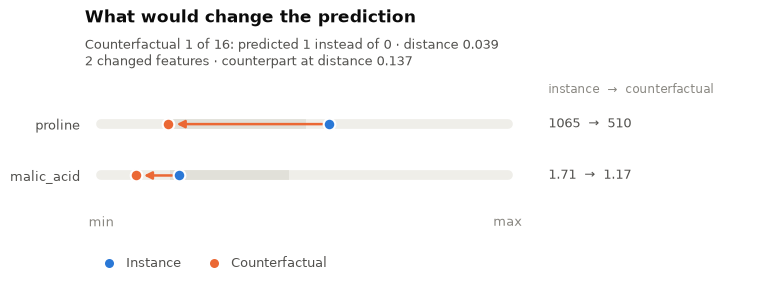

In [9]:
explanation.plot();

How to read it:

- **Rows.** There is one row per feature that the counterfactual changes, the largest change first. A change is measured as a fraction of the feature's range, so features of different units can be compared. Unchanged features are left out, so a counterfactual with a single change draws a single row.
- **Line.** The gray line is the range of the feature in the reference data, from its minimum to its maximum. The darker part holds the middle half of the examples (from the 25th to the 75th percentile), so you can see whether a value is common or extreme.
- **Dots.** The blue dot is the instance's value, the orange dot the counterfactual's, and the arrow goes from one to the other. The values are written on the right.
- **Subtitle.** It gives the counterfactual's position, its prediction against the instance's, its distance to the instance, its number of changed features and the distance to its counterpart.

`explanation.plot_changes(i)` draws the counterfactual at position `i`, and `max_features` limits the features shown. [plots.ipynb](../plots.ipynb) describes what every plot of NIFE has in common: drawing on your own figures, saving and changing the colors.

## Counterfactuals found by other libraries

`plots.plot_changes` takes the instance, a counterfactual and the reference data, and `evaluate_counterfactuals` takes the model and the reference data, so both work with counterfactuals that NIFE did not find. Here the counterfactual of each instance is simply the closest example of the data, in standardized units, that the model puts in another class:

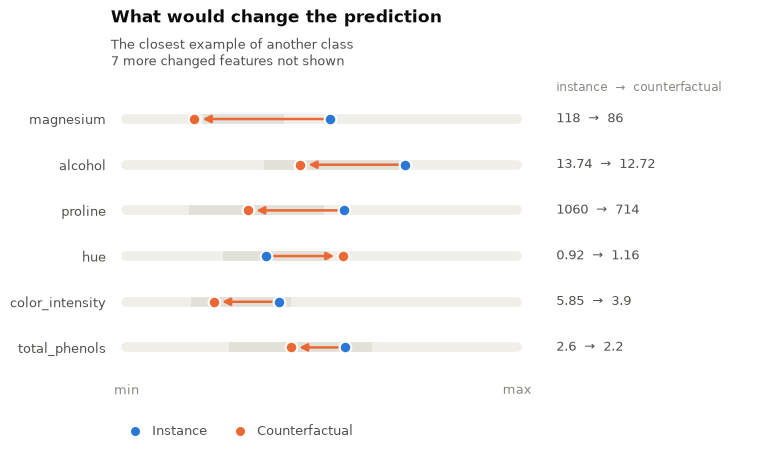

In [10]:
from nife.counterfactual import evaluate_counterfactuals, plots

predicted = pd.Series(model.predict(X), index=X.index)
rows = []
for position, (index, instance) in enumerate(instances.iterrows()):
    others = X[predicted != predicted[index]]
    distance = (((others - instance) / X.std()) ** 2).sum(axis=1)
    rows.append(others.loc[[distance.idxmin()]].assign(instance=position))
nearest = pd.concat(rows, ignore_index=True)

plots.plot_changes(instances.iloc[0], nearest.iloc[0], X, max_features=6, subtitle="The closest example of another class");

A real example of another class changes almost every feature, so it makes a poor counterfactual, as the metrics show:

In [11]:
evaluate_counterfactuals(instances, nearest, model, X)

coverage             1.00000
count                1.00000
validity             1.00000
proximity            0.15383
changed_features    12.75000
redundancy          12.30000
implausibility       0.00000
ynn                  0.72000
diversity                NaN
dtype: float64

## References

- Dandl, S., Molnar, C., Binder, M., & Bischl, B. (2020). Multi-objective counterfactual explanations. *Parallel Problem Solving from Nature (PPSN XVI)*.
- Gower, J. C. (1971). A general coefficient of similarity and some of its properties. *Biometrics*, 27(4), 857–871.
- Molnar, C. (2022). *Interpretable Machine Learning: A Guide for Making Black Box Models Explainable* (2nd ed.). https://christophm.github.io/interpretable-ml-book/
- Silva, J., Aguilar, E., & Salvini, R. (2026). Unveiling concise counterfactual explanations and feature relevance in machine learning through decision trees. *ICAART 2026*, 2941–2948. https://doi.org/10.5220/0014338700004052
- Wachter, S., Mittelstadt, B., & Russell, C. (2018). Counterfactual explanations without opening the black box: automated decisions and the GDPR. *Harvard Journal of Law & Technology*, 31(2), 841–887.